# L3 - PCA and k-means clustering (Ames Housing)

Goal: reduce the Ames Housing data with PCA and group the houses with k-means, without using the price.

What we do in this notebook:
1. prepare the data (cleaning from L1, encoding, scaling)
2. PCA: how much variance each component explains and how many components we need for 98%, 95%, 90% and 80%
3. k-means on each of the four reduced datasets, with the elbow method and silhouette plots to choose k
4. loadings: which features shape the most important principal components


## 1.1 Data preparation

The cleaning is the one from L1 (`L1/preprocessing.py`), imported in `l3_pipeline.py`. It fills the NaNs that
mean "no feature", imputes Lot Frontage (median per neighbourhood) and Electrical (mode), fixes inconsistent rows,
removes the 3 outliers and adds Total SF, Total Bath, House Age, Has Pool, Has Garage.

PCA and k-means can't work with missing values, so Garage Yr Blt (missing only for houses without a
garage) is filled with Year Built. SalePrice is removed from the features: the clusters should be found only from
the properties of the houses. We keep the price separately to describe the clusters later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from l3_pipeline import load_data

SEED = 42

df, price = load_data()
print("shape:", df.shape)
print("missing values left:", int(df.isna().sum().sum()))

shape: (2927, 84)
missing values left: 0


## 1.2 Encoding

- Ordinal columns (quality, condition, basement finish...) are mapped to numbers in their natural order,
  e.g. Kitchen Qual Po=1 ... Ex=5. Then Gd and Ex are close and Po and Ex are far apart, which makes sense.
- Nominal columns (Neighborhood, Roof Style, ...) are one-hot encoded. If we just numbered the neighbourhoods,
  k-means would think neighbourhood 0 and 1 are similar and 0 and 27 very different, only because of the
  alphabetical order. With one-hot every two different neighbourhoods have the same distance.

In [2]:
from l3_pipeline import encode

X = encode(df)
FEATURE_COLUMNS = X.columns 

binary = [c for c in X.columns if set(X[c].unique()) <= {0, 1}]
print("shape:", X.shape)
print("missing values:", int(X.isna().sum().sum()))
print("binary (0/1) columns:", len(binary), "| other numeric columns:", X.shape[1] - len(binary))
print("binary columns with less than 1% ones:", int((X[binary].mean() < 0.01).sum()))

shape: (2927, 249)
missing values: 0
binary (0/1) columns: 190 | other numeric columns: 59
binary columns with less than 1% ones: 79


After encoding we have 249 columns: 59 "normal" numeric ones (areas, years, ordinal scores...) and 190 binary
0/1 columns, mostly from one-hot. 79 of the binary columns are 1 for less than 1% of the houses (rare
neighbourhoods, roof materials). This will matter for the scaling in the next step.

## 1.3  Scaling

PCA looks for directions with a lot of variance and k-means uses distances, so both depend on the units.
Without scaling, Lot Area (thousands of square feet) would completely dominate Overall Qual (1-10).
We use min-max scaling: every column is mapped to [0, 1]. The 0/1 columns stay
the same, the continuous ones are squeezed into [0, 1].

The weak point of min-max are extreme values. Lot Area has a median of ~9,400 but one property with 215,245,
so after min-max a typical house is only at ~0.04. For the comparisons in the other part of the lab the
pipeline can also use StandardScaler and log(1 + x) on the skewed area columns (`LOG_COLUMNS`).

In [3]:
from l3_pipeline import make_scaler, apply_log, LOG_COLUMNS

scaler = make_scaler("minmax")
X_scaled = scaler.fit_transform(X)      

print("shape:", X_scaled.shape)
print("range:", X_scaled.min(), "to", X_scaled.max())

# effect of an extreme value: Lot Area
lot = X[["Lot Area"]]
lot_minmax = make_scaler("minmax").fit_transform(lot)
lot_log_minmax = make_scaler("minmax").fit_transform(apply_log(X)[["Lot Area"]])
print(f"Lot Area: median {lot['Lot Area'].median():,.0f}, max {lot['Lot Area'].max():,.0f}")
print(f"typical house after min-max: {np.median(lot_minmax):.3f}")
print(f"typical house after log + min-max: {np.median(lot_log_minmax):.3f}")

shape: (2927, 249)
range: 0.0 to 1.0
Lot Area: median 9,430, max 215,245
typical house after min-max: 0.038
typical house after log + min-max: 0.388


All 249 columns are now between 0 and 1. The Lot Area example shows the problem of min-max with extreme values:
because of one huge property, a typical house ends up at 0.038, so almost all houses are squeezed close to 0.
With log first, the typical house is at 0.39 and the values are spread over the whole range.
In this part we use min-max without log as asked in the task; the other combinations are compared in the
next part of the lab.

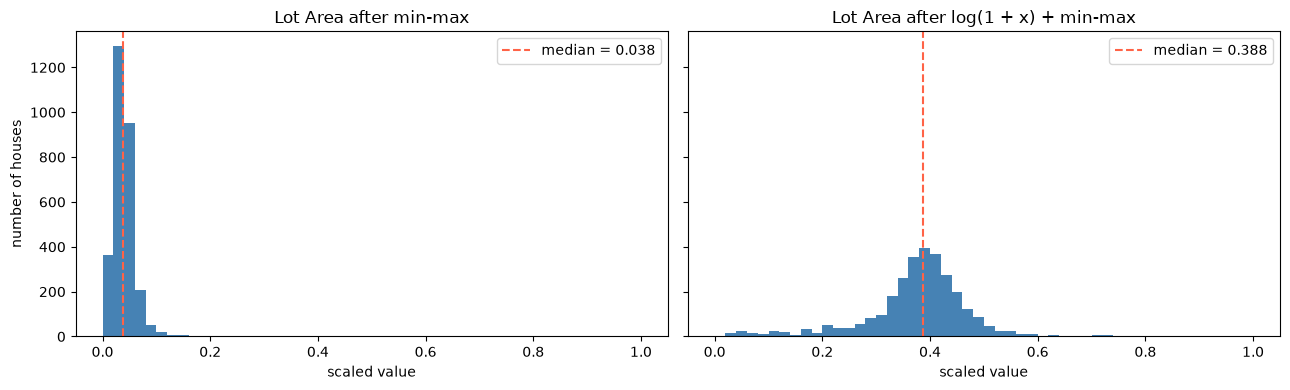

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, values, title in [(axes[0], lot_minmax.ravel(), "min-max"),
                          (axes[1], lot_log_minmax.ravel(), "log(1 + x) + min-max")]:
    ax.hist(values, bins=50, color="steelblue")
    ax.axvline(np.median(values), color="tomato", ls="--", label=f"median = {np.median(values):.3f}")
    ax.set_title(f"Lot Area after {title}")
    ax.set_xlabel("scaled value")
    ax.legend()
axes[0].set_ylabel("number of houses")
plt.tight_layout()
plt.show()


For k-means this means: with plain min-max, two houses with a normal and a twice as big lot are still almost at
the same position on this axis, so Lot Area hardly influences the distances. The log transform gives these
differences more weight. Here we keep plain min-max as asked in the task; the effect of the log transform on the
clusters is compared in the next part of the lab.

## 2 PCA

PCA finds new axes (principal components): PC1 is the direction in which the houses differ the most, PC2 the
next one perpendicular to PC1, and so on. `explained_variance_ratio_` tells how much of the total variance each
component explains. The components are sorted, so to keep e.g. 98% of the variance we take the first components
until their cumulative sum reaches 98%.

We fit PCA once with all components. The four reduced datasets are just the first k columns of the same result,
so PC1 and PC2 are the same in all of them.

In [5]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=SEED).fit(X_scaled)
ratio = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratio)

print("number of components:", len(ratio))
print(pd.DataFrame({"explained variance (%)": (ratio[:10] * 100).round(2),
                    "cumulative (%)": (cumulative[:10] * 100).round(2)},
                   index=[f"PC{i}" for i in range(1, 11)]))

number of components: 249
      explained variance (%)  cumulative (%)
PC1                    13.52           13.52
PC2                     8.58           22.10
PC3                     5.36           27.46
PC4                     4.11           31.57
PC5                     3.54           35.11
PC6                     2.98           38.10
PC7                     2.87           40.97
PC8                     2.80           43.76
PC9                     2.73           46.49
PC10                    2.38           48.88


In [6]:
THRESHOLDS = [0.98, 0.95, 0.90, 0.80]
N_COMPONENTS = {t: int(np.searchsorted(cumulative, t) + 1) for t in THRESHOLDS}

pd.DataFrame({"components": N_COMPONENTS,
              "% of the 249 features": {t: round(100 * k / X.shape[1], 1) for t, k in N_COMPONENTS.items()}},
             ).rename(index=lambda t: f"{int(t*100)}% variance")

,components,% of the 249 features
98% variance,122,49.0
95% variance,87,34.9
90% variance,62,24.9
80% variance,38,15.3


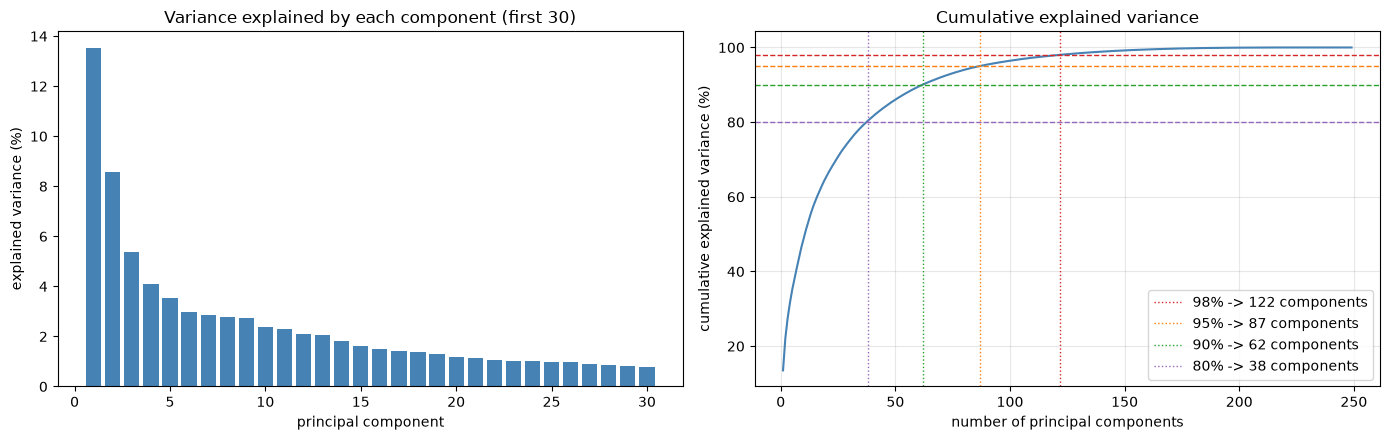

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(range(1, 31), ratio[:30] * 100, color="steelblue")
axes[0].set_xlabel("principal component")
axes[0].set_ylabel("explained variance (%)")
axes[0].set_title("Variance explained by each component (first 30)")

axes[1].plot(range(1, len(cumulative) + 1), cumulative * 100, color="steelblue")
for t, col in zip(THRESHOLDS, ["tab:red", "tab:orange", "tab:green", "tab:purple"]):
    axes[1].axhline(t * 100, color=col, ls="--", lw=1)
    axes[1].axvline(N_COMPONENTS[t], color=col, ls=":", lw=1, label=f"{int(t*100)}% -> {N_COMPONENTS[t]} components")
axes[1].set_xlabel("number of principal components")
axes[1].set_ylabel("cumulative explained variance (%)")
axes[1].set_title("Cumulative explained variance")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()

The first components carry most of the information (PC1 13.5%, PC2 8.6%), after about PC10 each one adds less
than 2.5%. For 80% of the variance we need 38 components, for 90% 62, for 95% 87 and for 98% 122 of 249. The curve
gets flat at the end, so the last components add almost nothing and are mostly noise. PC1 and PC2 together explain
only 22%, so a 2D plot shows just part of the structure.

In [8]:
X_pca_full = pca_full.transform(X_scaled)
X_pca = {t: X_pca_full[:, :k] for t, k in N_COMPONENTS.items()}
for t, data in X_pca.items():
    print(f"{int(t*100)}%: {data.shape}")

98%: (2927, 122)
95%: (2927, 87)
90%: (2927, 62)
80%: (2927, 38)


Two things to note:
- We still need quite many components. One reason are the 190 one-hot columns: many of them, especially the rare
  ones, are almost independent of the rest, so PCA can't combine them with other columns and each takes its own
  small component.
- The first two components together explain only 22% of the variance, so a scatter plot of PC1 vs PC2 shows
  just a part of the structure of the data.

## 3 k-means

We train k-means on each of the four reduced datasets for k = 2 to 10 (`n_init=10`: 10 runs with different
starting centroids, the best one is kept). To choose k we use:
- the elbow method: inertia = sum of squared distances of the houses to their centroid. It always decreases with
  k; we look for the point after which it decreases much slower.
- the silhouette score: for each house it compares the distance to its own cluster with the distance to the
  closest other cluster. Close to 1 = clearly in its cluster, close to 0 = at the border, negative = probably in
  the wrong cluster.

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

K_RANGE = range(2, 11)
rows = []
for t in THRESHOLDS:
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_pca[t])
        rows.append({"threshold": t, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X_pca[t], km.labels_),
                     "cluster sizes": np.bincount(km.labels_).tolist()})
km_results = pd.DataFrame(rows)
print(f"trained {len(km_results)} models")

trained 36 models


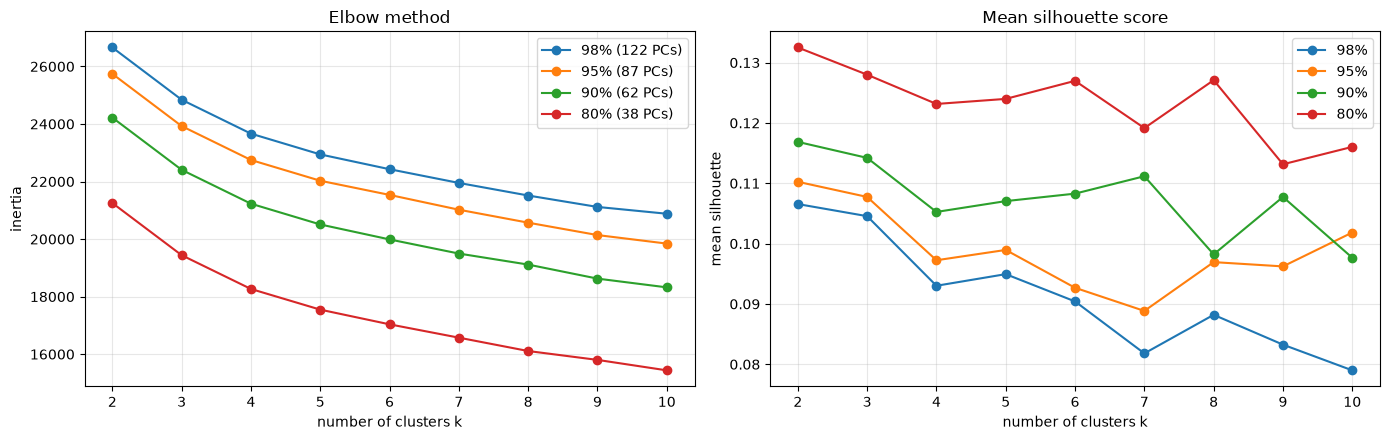

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for t in THRESHOLDS:
    g = km_results[km_results.threshold == t]
    axes[0].plot(g.k, g.inertia, "o-", label=f"{int(t*100)}% ({N_COMPONENTS[t]} PCs)")
    axes[1].plot(g.k, g.silhouette, "o-", label=f"{int(t*100)}%")
axes[0].set(xlabel="number of clusters k", ylabel="inertia", title="Elbow method")
axes[1].set(xlabel="number of clusters k", ylabel="mean silhouette", title="Mean silhouette score")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

Left plot: the inertia drops a lot until k=3-4, after that the curve is almost straight, so the elbow is around
k=3-4 (not very sharp). Right plot: the silhouette is highest for k=2, k=3 is almost as good, k=4 drops. All values
are low (~0.1), so the clusters are not clearly separated. The 80% line is always the highest because the last
components are mostly noise. The inertia lines can't be compared with each other, 80% is lower only because less
variance is kept.

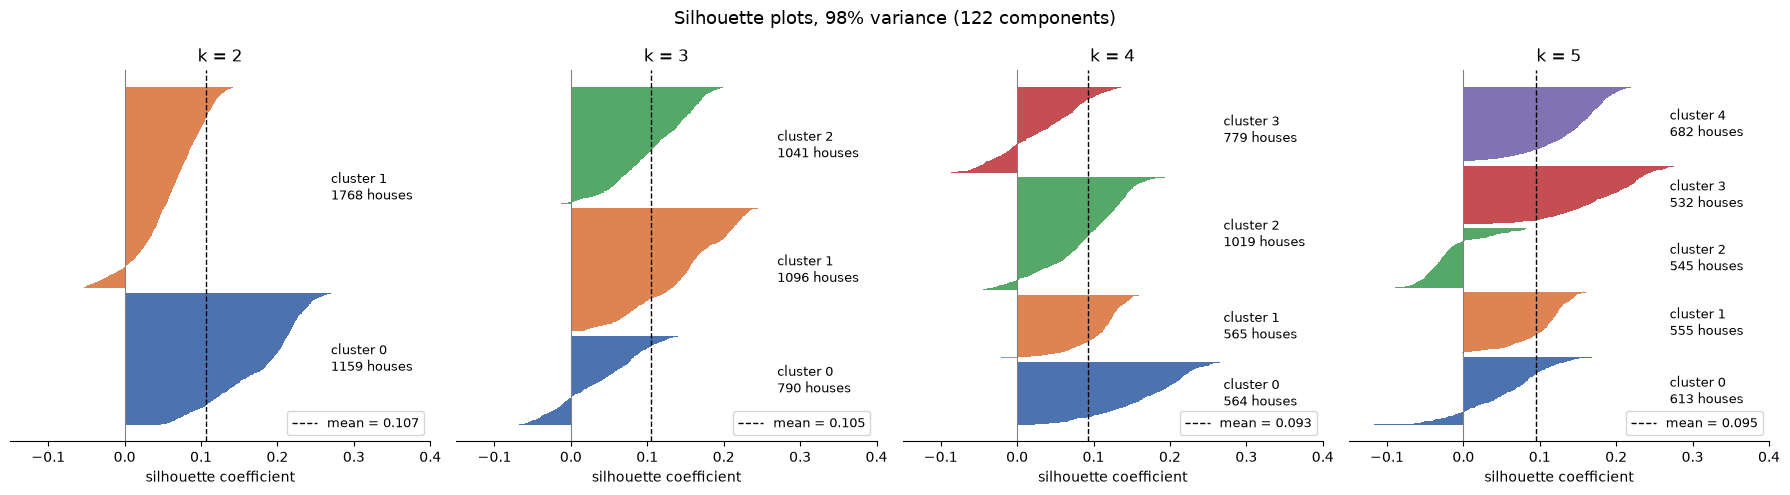

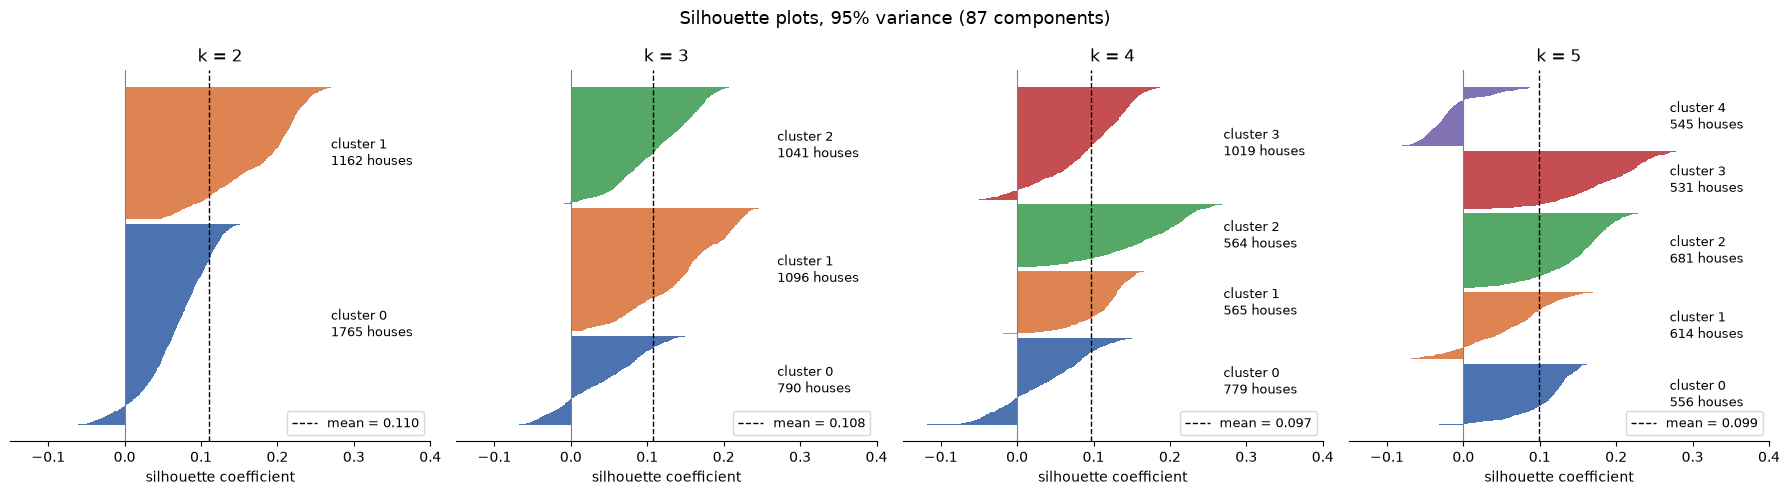

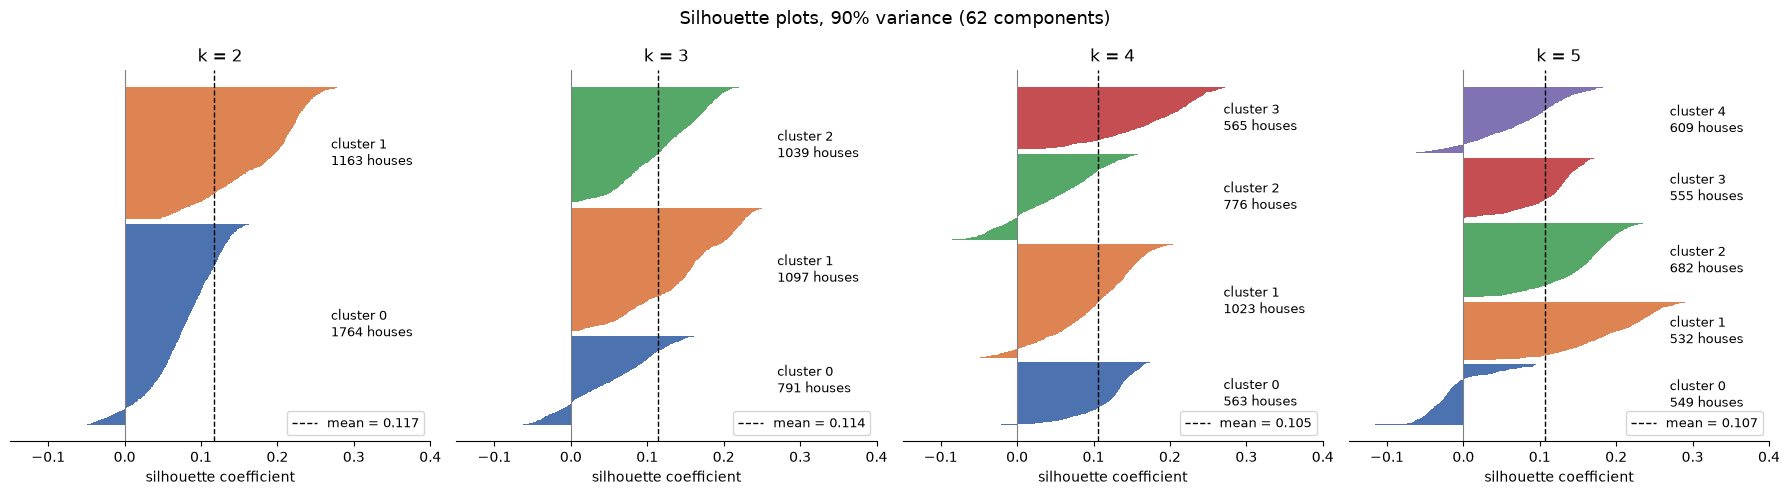

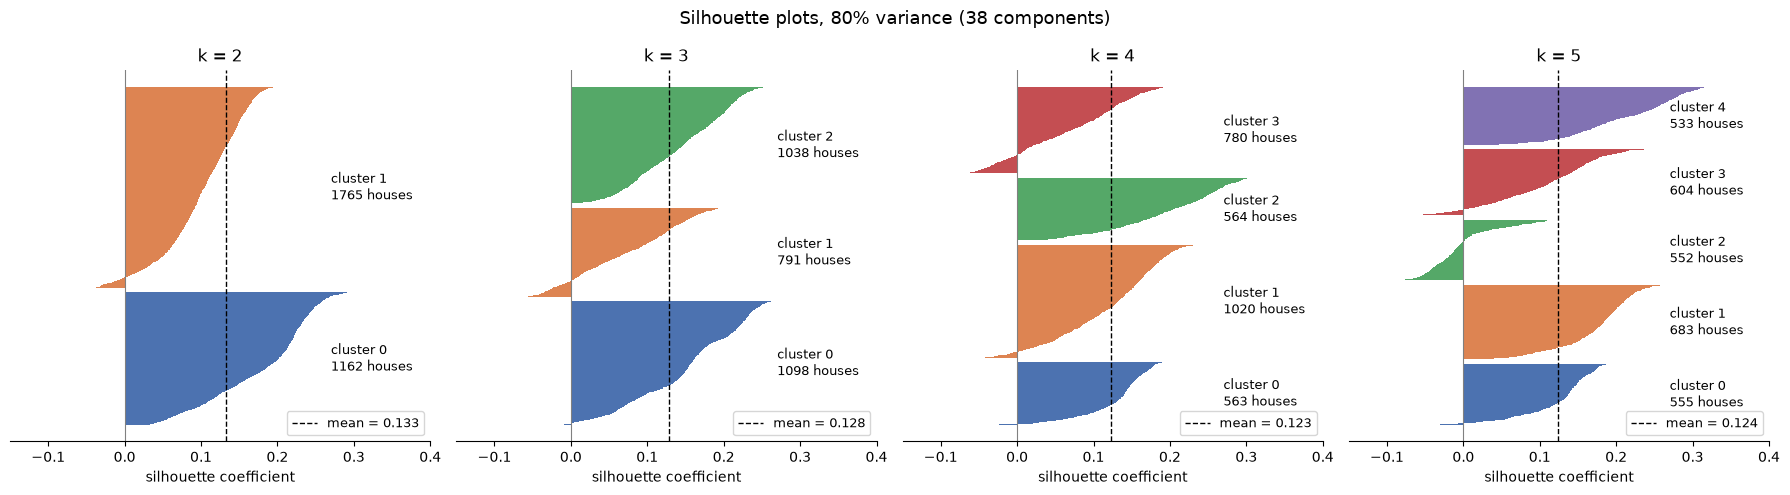

In [11]:
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]


def silhouette_plot(ax, data, k):
    labels = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(data)
    scores = silhouette_samples(data, labels)
    y = 0
    for c in range(k):
        values = np.sort(scores[labels == c])                       # houses of cluster c, sorted
        ax.barh(np.arange(y, y + len(values)), values, height=1.0, color=COLORS[c], edgecolor="none")
        ax.text(0.27, y + len(values) / 2, f"cluster {c}\n{len(values)} houses", va="center", fontsize=9)
        y += len(values) + 40                                       # gap between clusters
    ax.axvline(scores.mean(), color="black", ls="--", lw=1, label=f"mean = {scores.mean():.3f}")
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_xlim(-0.15, 0.4)
    ax.set_yticks([])
    ax.set_title(f"k = {k}")
    ax.set_xlabel("silhouette coefficient")
    ax.legend(loc="lower right", fontsize=9)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)


for t in THRESHOLDS:
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))
    for ax, k in zip(axes, [2, 3, 4, 5]):
        silhouette_plot(ax, X_pca[t], k)
    fig.suptitle(f"Silhouette plots, {int(t*100)}% variance ({N_COMPONENTS[t]} components)", fontsize=13)
    plt.tight_layout()
    plt.show()

Each colored shape is one cluster and each thin horizontal line in it is one house, sorted by its silhouette
value; the height of a shape is the size of the cluster and the dashed line is the mean. Values left of 0 are
houses that are closer to another cluster. For k=3 the three clusters have similar sizes and almost all houses
are positive. For k=4 and k=5 more houses are negative, and for k=5 one cluster is almost completely negative,
so it's a forced split. This supports k=3. The values are low overall (max ~0.25), so even well placed houses
are not far from the other clusters.

In [12]:
K_FINAL = 3
kmeans_models = {t: KMeans(n_clusters=K_FINAL, n_init=10, random_state=SEED).fit(X_pca[t]) for t in THRESHOLDS}
cluster_labels = {t: m.labels_ for t, m in kmeans_models.items()}

for t, m in kmeans_models.items():
    print(f"{int(t*100)}%: cluster sizes {np.bincount(m.labels_).tolist()}")

98%: cluster sizes [790, 1096, 1041]
95%: cluster sizes [790, 1096, 1041]
90%: cluster sizes [791, 1097, 1039]
80%: cluster sizes [1098, 791, 1038]


We choose k=3: elbow and silhouette both point to 3-4, and k=3 has three clusters of similar size with fewer
negative silhouette values than k=4. Two clusters would only split the houses into "big/new" and "small/old".
The threshold hardly changes the result: for k=3 the cluster sizes are almost the same for all four datasets,
because the distances are dominated by the first components, which are the same everywhere.

In [13]:
loadings = pd.DataFrame(pca_full.components_.T * np.sqrt(pca_full.explained_variance_),
                        index=FEATURE_COLUMNS,
                        columns=[f"PC{i}" for i in range(1, len(FEATURE_COLUMNS) + 1)])
loadings.shape

(249, 249)

## 4 Loadings

`loadings = pca.components_.T * np.sqrt(pca.explained_variance_)` shows how strongly each original feature moves
together with each principal component. The sign tells the direction, the absolute value how important the feature
is for the component. To understand a component we look at the features with the largest positive and negative
loadings.

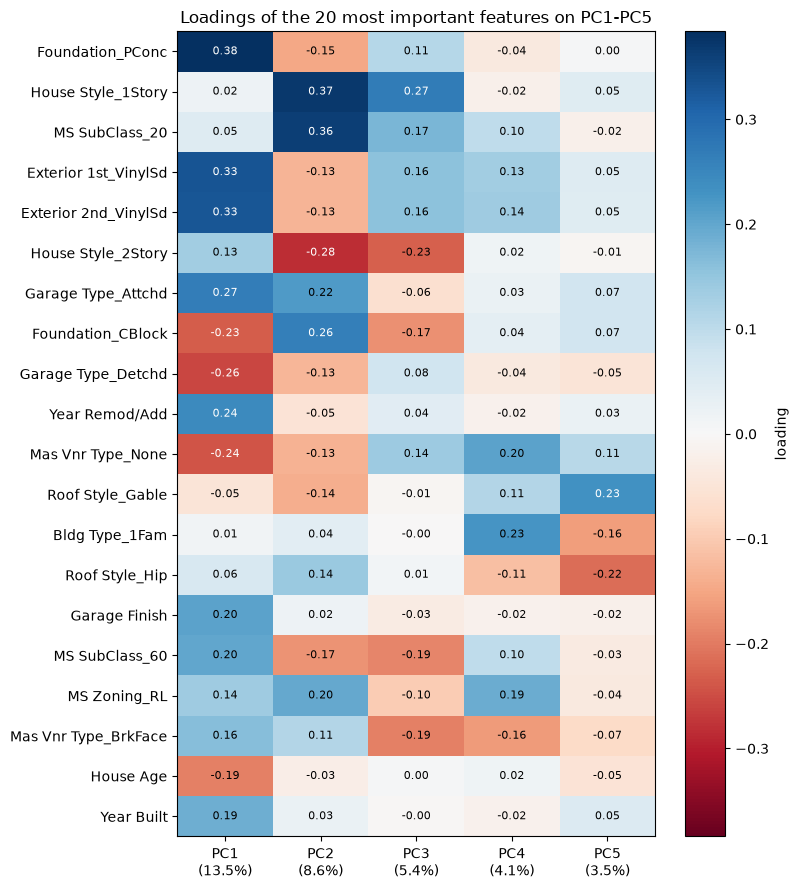

In [14]:
pcs = ["PC1", "PC2", "PC3", "PC4", "PC5"]
top = loadings[pcs].abs().max(axis=1).sort_values(ascending=False).index[:20]   # 20 most important features
H = loadings.loc[top, pcs]
lim = np.abs(H.values).max()

fig, ax = plt.subplots(figsize=(8, 9))
im = ax.imshow(H.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(pcs)), [f"{pc}\n({ratio[i] * 100:.1f}%)" for i, pc in enumerate(pcs)])
ax.set_yticks(range(len(top)), top)
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        v = H.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * lim else "black")
plt.colorbar(im, label="loading")
ax.set_title("Loadings of the 20 most important features on PC1-PC5")
plt.tight_layout()
plt.show()

PC1 (13.5%) separates new from old houses: positive loadings for poured concrete foundation, vinyl siding,
attached garage and recent build/remodel years, negative for detached garage, cinder block foundation and a high
house age. PC2 (8.6%) separates one-story from two-story houses. PC3 is a mix of both and harder to name.

In [15]:

variances = pd.Series(X_scaled.var(axis=0), index=FEATURE_COLUMNS)
print(variances[["Foundation_PConc", "Year Built", "Overall Qual", "Gr Liv Area", "Lot Area"]].round(4))
print(f"share of the total variance in the 0/1 columns: {variances[binary].sum() / variances.sum():.0%}")

Foundation_PConc    0.2471
Year Built          0.0480
Overall Qual        0.0244
Gr Liv Area         0.0141
Lot Area            0.0013
dtype: float64
share of the total variance in the 0/1 columns: 82%


Most important features are one-hot columns, not areas or quality. The reason is min-max scaling: a 0/1 column that
is 1 for half of the houses has variance ~0.25, while continuous columns squeezed by extreme values have much less
(Gr Liv Area 0.014, Lot Area 0.001). 82% of the total variance is in the 0/1 columns, so PCA mostly follows them.
They are still strongly related to the age of the house, which is why PC1 works as a "new vs old" axis.

## 5 Final model

Min-max scaling, no log, PCA with 95% of the variance (87 components) and k-means with k=3. The thresholds give
almost the same clusters, and 95% keeps nearly all the information with about a third of the features.

In [16]:
FINAL_THRESHOLD = 0.95
final_scaler = scaler                                  # min-max, fitted in 1.3
final_pca = pca_full                                   # fitted in 2
final_n_components = N_COMPONENTS[FINAL_THRESHOLD]     # 87
final_kmeans = kmeans_models[FINAL_THRESHOLD]          # k=3
final_labels = final_kmeans.labels_

print(f"final model: {final_n_components} components, k={K_FINAL}, cluster sizes {np.bincount(final_labels).tolist()}")

final model: 87 components, k=3, cluster sizes [790, 1096, 1041]
